# Pearson-korreláció
A korreláció **két numerikus változó közötti kapcsolat erősségét és irányát** méri. A Pearson-korreláció **egy statisztikai mérőszám**, amely két folytonos numerikus változó közötti lineáris kapcsolat erősségét és irányát számszerűsíti.

- Erős lineáris kapcsolatokkal rendelkező jellemzők kiválasztására szolgál a **prediktív modellezéshez**.
- Segít azonosítani, hogy mely **változók növekednek vagy csökkennek** együtt.
- **Redundanciát észlel** a szorosan korrelált változók között a multikollinearitás elkerülése érdekében.
- **Érzékeny a kiugró értékekre**, amelyek jelentősen befolyásolhatják a korrelációs értéket.


## Hogyan működik a Pearson-korreláció?
A Pearson-korreláció egy szám, amely megmutatja, hogy két érték mennyire szorosan kapcsolódik lineárisan egymáshoz. Az eredmény -1 és +1 között van:

- +1: Tökéletes pozitív kapcsolat (mindkettő együtt növekszik)
- -1: Tökéletes negatív kapcsolat (az egyik növeli, a másik csökkenti)
- 0: Nincs lineáris kapcsolat

## Pearson-korrelációs képlet

$$r = \frac{\sum (x - m_x)(y - m_y)}{\sqrt{\sum (x - m_x)^2 \sum (y - m_y)^2}}$$

- **$r$**: a Pearson-féle korrelációs együttható értéke (ahol $-1 \le r \le 1$).
- **$x$ és $y$:** a két vizsgált változó megfelelő adatpárjai.
- **$m_x$:** az $X$ változó adatainak átlaga ($\bar{x}$).
- **$m_y$:** a $Y$ változó adatainak átlaga ($\bar{y}$).
- **$\sum (x - m_x)(y - m_y)$:** az $X$ és $Y$ változók kovarianciájának számlálója (az eltérések keresztösszege).
- **$\sum (x - m_x)^2$:** az $X$ változó eltérésnégyzet-összege.
- **$\sum (y - m_y)^2$:** a $Y$ változó eltérésnégyzet-összege.

## A korrelációs módszerek típusai
Két fő típusa van:

### 1. Paraméteres korreláció
- Lineáris kapcsolatokat mér a folytonos változók között
- Normális eloszlást feltételez és érzékeny a kiugró értékekre
- A Pearson-korreláció a leggyakrabban használt módszer

### 2. Nemparametrikus korreláció
- Nem normális vagy ordinális adatokhoz és nemlineáris (monoton) kapcsolatokhoz használják.
- Rangsorolt ​​adatok alapján, így jobban ellenáll a kiugró értékeknek
- Gyakori módszerek közé tartozik a Spearman-féle Rho és a Kendall-féle Tau.


## Pearson-korreláció implementálása Pythonban
A Pythonban található egy beépített `pearsonr() `metódus a `scipy.stats modulból` a Pearson-korreláció megkereséséhez.

Szintaxis: 

`from scipy.stats import pearsonr

pearsonr(x, y)`

> - **Paraméterek**: x, y a numerikus listák vagy sorozatok.
> - **Visszatérési típus**: Egy tuple (korrelációs együttható, p-érték)


In [2]:
import pandas as pd
from scipy.stats import pearsonr

df = pd.read_csv("files/Auto.csv")

# Convert dataframe into series
l1 = df['weight']
l2 = df['mpg']

# Apply the pearsonr()
corr, _ = pearsonr(l1, l2)
print('Pearsons correlation: %.3f' % corr)

Pearsons correlation: -0.878


## A korreláció megértése Anscombe-kvartett segítségével

Az **Anscombe-kvartett** azt mutatja, hogy a **korrelációs számok félrevezetőek lehetnek**. A négy kis adathalmaz szinte azonos Pearson-korrelációval rendelkezik, **de nagyon eltérő mintázatokat mutatnak, amikor ugyanazt a korrelációt ábrázolják**, a különböző mintázatok pedig az adatok vizualizálásának fontosságát hangsúlyozzák.

- Töltsük be a négy adathalmazt egy CSV-fájlból.
- Számítsuk ki a Pearson-korrelációt minden adathalmazra.
- Ábrázoljuk az összes adathalmazt, hogy lássuk, hogyan különböznek vizuálisan.


Dataset I: Pearson correlation = 0.816
Dataset II: Pearson correlation = 0.816
Dataset III: Pearson correlation = 0.816
Dataset IV: Pearson correlation = 0.817


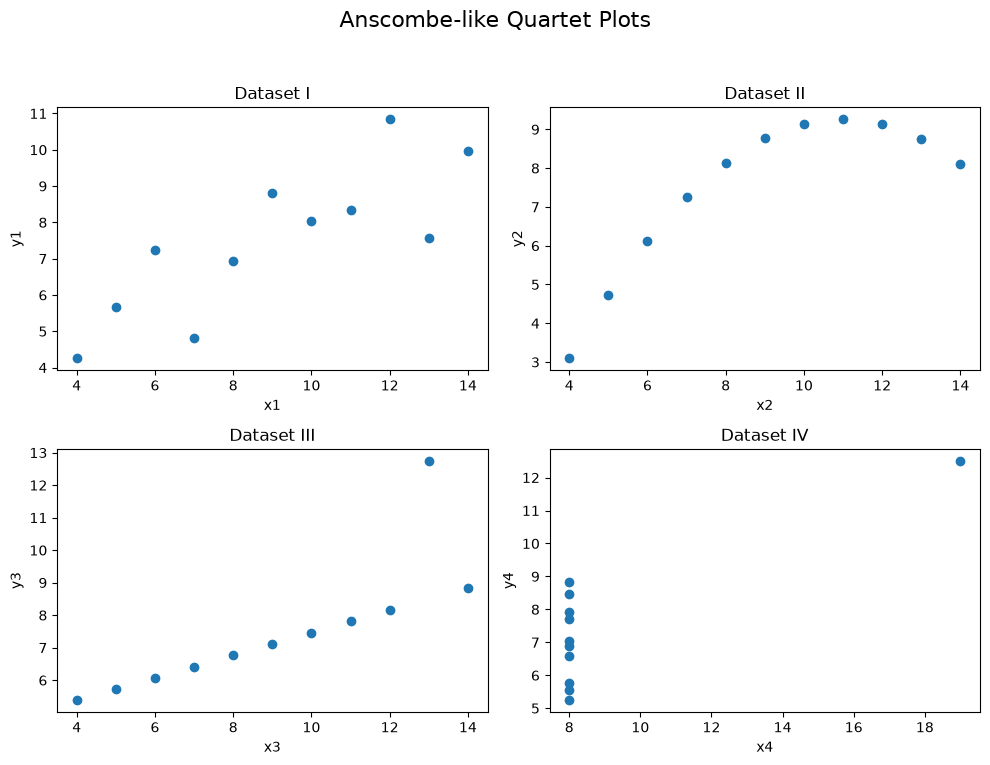

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

df = pd.read_csv("files/anscombe.csv")

# Az adathalmazok neveinek tárolása a ciklushoz
datasets = {
    "I": ("x1", "y1"),
    "II": ("x2", "y2"),
    "III": ("x3", "y3"),
    "IV": ("x4", "y4")
}

# Végigiterálás az egyes adathalmazokon és a Pearson-korreláció kiszámítása
for name, (x_col, y_col) in datasets.items():
    x = df[x_col]
    y = df[y_col]
    corr, _ = pearsonr(x, y)
    print(f"Dataset {name}: Pearson correlation = {corr:.3f}")

# Az adathalmazok ábrázolása 
fig, axs = plt.subplots(2, 2, figsize=(10, 8))
fig.suptitle('Anscombe-like Quartet Plots', fontsize=16)

for i, (name, (x_col, y_col)) in enumerate(datasets.items()):
    row = i // 2
    col = i % 2
    axs[row, col].scatter(df[x_col], df[y_col])
    axs[row, col].set_title(f"Dataset {name}")
    axs[row, col].set_xlabel(x_col)
    axs[row, col].set_ylabel(y_col)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()